# CSC 4233 NLP Mid-Term Project - Group G07
**Sentiment Classification of IMDB Movie Reviews Using Classical NLP Techniques**
Dataset: IMDB Large Movie Review Dataset (Maas et al., ACL 2011)

Members: Sadiya Mohon Auti (23-52092-2) |  Tasnim Tabassum Mim (23-50971-1)

**How to run:** Runtime > Run all. No uploads needed. All seeds fixed (SEED = 42). The dataset is read from a public GitHub/Google Drive link (see Section 2).

**Pipeline:** setup -> load data -> dedupe -> sample & split -> EDA -> preprocessing -> baseline -> ablation -> representations & tuning -> test evaluation -> error analysis -> report numbers.


## 1. Setup
Install gensim (Word2Vec), import everything, fix random seed, download NLTK resources.

In [120]:
!pip -q install gensim nltk scikit-learn matplotlib pandas numpy gdown

Imports, the fixed random seed (`SEED = 42`) and the NLTK resources (stop-word list, WordNet) used by the preprocessing pipeline.

In [121]:
import re, random, platform, warnings
from collections import Counter
from functools import lru_cache
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import nltk, sklearn, gensim
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, confusion_matrix, classification_report)
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_colwidth", 220)

for pkg in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

## 2. Load the dataset
IMDB Large Movie Review Dataset (Maas et al., 2011): 25,000 train + 25,000 test = 50,000 labelled reviews.
The course guideline requires datasets from Hugging Face/Kaggle/UCI to be **hosted on GitHub or Google Drive**, so the notebook reads a CSV copy of the original data (train split followed by test split, columns `text`, `label`; 0 = negative, 1 = positive) from a public link. The copy was exported once from the Hugging Face mirror `stanfordnlp/imdb` without any modification.


In [122]:

import pandas as pd
import gdown

# Paste your NEW Google Drive link here
DATA_URL = "https://drive.google.com/file/d/1BA-3pOfl81DTWpD-5Nb-Pk1m1jBqzieE/view?usp=sharing"

# Download dataset from Google Drive
gdown.download(url=DATA_URL, output="imdb_50000.csv", fuzzy=True, quiet=True)
df = pd.read_csv("imdb_50000.csv")

# Keep only required columns
df = df[["text", "label"]]

# Verify labels
assert set(df["label"].unique()) == {0, 1}, "unexpected labels"
print("Total labelled reviews:", len(df))
print(df["label"].value_counts())
df.head()

Total labelled reviews: 50000
label
0    25000
1    25000
Name: count, dtype: int64


,text,label
0,I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to ente...,0
1,"""I Am Curious: Yellow"" is a risible and pretentious steaming pile. It doesn't matter what one's political views are because this film can hardly be taken seriously on any level. As for the claim that frontal male nud...",0
2,If only to avoid making this type of film in the future. This film is interesting as an experiment but tells no cogent story.<br /><br />One might feel virtuous for sitting thru it because it touches on so many IMPOR...,0
3,"This film was probably inspired by Godard's Masculin, féminin and I urge you to see that film instead.<br /><br />The film has two strong elements and those are, (1) the realistic acting (2) the impressive, undeserve...",0
4,"Oh, brother...after hearing about this ridiculous film for umpteen years all I can think of is that old Peggy Lee song..<br /><br />""Is that all there is??"" ...I was just an early teen when this smoked fish hit the U...",0



## 3. Remove duplicate reviews
Data leakage prevention: same review cannot appear in train and test.

In [123]:
n_before = len(df)
conflict = int(df.groupby("text")["label"].nunique().gt(1).sum())
df = df.drop_duplicates(subset="text", keep="first").reset_index(drop=True)
n_after = len(df)
n_removed = n_before - n_after
print(f"Before: {n_before} | After: {n_after} | Duplicates removed: {n_removed}")
print("Texts with conflicting labels:", conflict)
print(df["label"].value_counts())

Before: 50000 | After: 49582 | Duplicates removed: 418
Texts with conflicting labels: 0
label
1    24884
0    24698
Name: count, dtype: int64


## 4. Stratified sample (10,000) and 70/15/15 split

In [124]:
N_PER_CLASS = 5000
sample = pd.concat([df[df["label"] == lab].sample(N_PER_CLASS, random_state=SEED) for lab in (0, 1)],
                   ignore_index=True)
train_df, temp_df = train_test_split(sample, test_size=0.30, stratify=sample["label"], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s} n={len(d):5d}  positive share={d['label'].mean():.3f}")
sample.to_csv("imdb_sample_10000.csv", index=False)

train n= 7000  positive share=0.500
val   n= 1500  positive share=0.500
test  n= 1500  positive share=0.500


## 5. Exploratory Data Analysis (EDA)
Class balance, review length, top words per class.

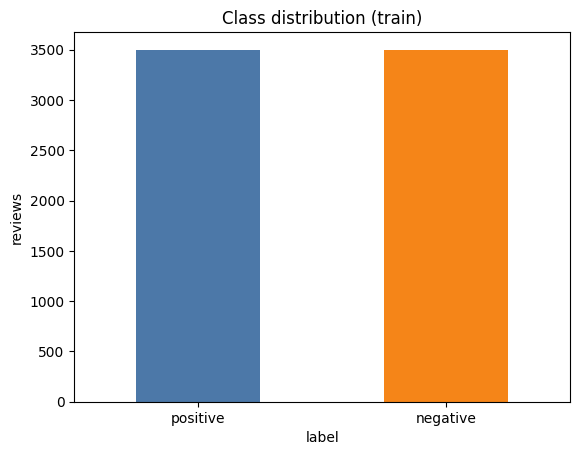

Interpretation (Fig. 1): the training set has 3500 negative and 3500 positive reviews, so the data is balanced (not imbalanced).


In [125]:
# Figure 1: class distribution (train)
counts = train_df["label"].map({0: "negative", 1: "positive"}).value_counts()
ax = counts.plot(kind="bar", color=["#4C78A8", "#F58518"])
ax.set_title("Class distribution (train)"); ax.set_ylabel("reviews"); plt.xticks(rotation=0)
plt.savefig("fig1_class_distribution.png", dpi=200, bbox_inches="tight"); plt.show()
print(f"Interpretation (Fig. 1): the training set has {counts['negative']} negative and {counts['positive']} positive reviews, "
      f"so the data is {'balanced (not imbalanced)' if abs(counts['negative']-counts['positive'])<=0.05*len(train_df) else 'imbalanced'}.")

**Figure 2 - review length.** Word counts per review (clipped at 1000 for plotting) with summary statistics per class; needed to judge how skewed the lengths are.

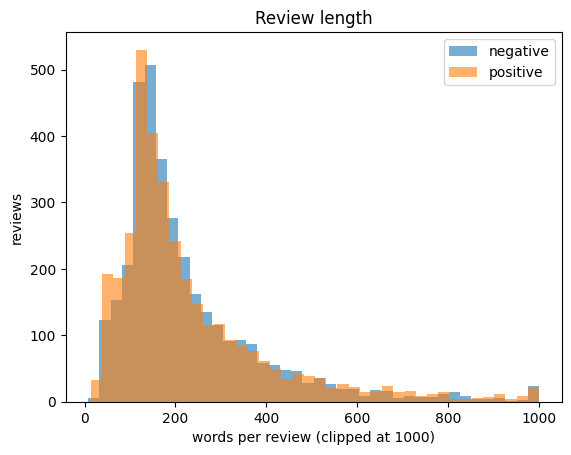

        count   mean    std   min    25%    50%    75%     max
label                                                         
0      3500.0  229.7  165.9   8.0  128.0  175.0  279.0  1522.0
1      3500.0  233.0  183.1  14.0  122.0  171.0  286.0  2278.0
Interpretation (Fig. 2): mean length = 231 words, median = 173 words, longest = 2278 words; mean > median, so the distribution is right-skewed with a few very long reviews.


In [126]:
# Figure 2: review length (words) by class
train_df["n_words"] = train_df["text"].str.split().str.len()
for lab, nm in [(0, "negative"), (1, "positive")]:
    plt.hist(train_df.loc[train_df.label == lab, "n_words"].clip(upper=1000), bins=40, alpha=0.6, label=nm)
plt.legend(); plt.xlabel("words per review (clipped at 1000)"); plt.ylabel("reviews"); plt.title("Review length")
plt.savefig("fig2_review_length.png", dpi=200, bbox_inches="tight"); plt.show()
stats = train_df.groupby("label")["n_words"].describe().round(1)
print(stats)
mean_, med_ = train_df["n_words"].mean(), train_df["n_words"].median()
print(f"Interpretation (Fig. 2): mean length = {mean_:.0f} words, median = {med_:.0f} words, longest = {train_df['n_words'].max()} words; "
      f"{'mean > median, so the distribution is right-skewed with a few very long reviews' if mean_>med_ else 'mean <= median, so the distribution is not right-skewed'}.")

**Figure 3 - most frequent words per class.** Light cleaning (HTML removed, stop-words removed, `movie`/`film` excluded) so that content words become visible; we also print which words are shared between the two classes.

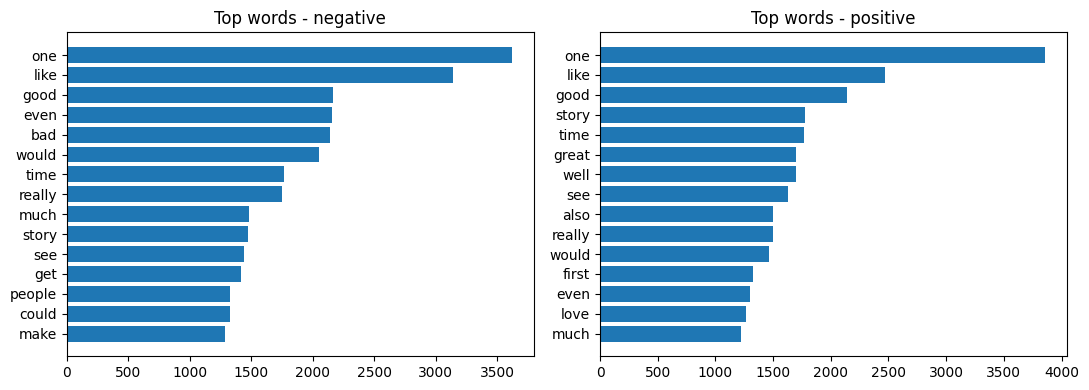

Shared in both top-15 lists: ['even', 'good', 'like', 'much', 'one', 'really', 'see', 'story', 'time', 'would']
Only negative: ['bad', 'could', 'get', 'make', 'people']
Only positive: ['also', 'first', 'great', 'love', 'well']
Interpretation (Fig. 3): 10 of the top-15 words are shared by both classes, so raw frequency alone separates the classes only weakly; the class-specific words listed above are the clearest sentiment signal.


In [127]:
# Figure 3: top-15 words per class (light cleaning + stop-word removal)
sw = set(stopwords.words("english")) | {"br", "movie", "film"}
def simple_tokens(t):
    t = re.sub(r"<[^>]+>", " ", t.lower())
    return [w for w in re.findall(r"[a-z]+", t) if w not in sw and len(w) > 2]
top15 = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (lab, nm) in zip(axes, [(0, "negative"), (1, "positive")]):
    cnt = Counter(w for t in train_df.loc[train_df.label == lab, "text"] for w in simple_tokens(t))
    words, vals = zip(*cnt.most_common(15)); top15[lab] = list(words)
    ax.barh(words[::-1], vals[::-1]); ax.set_title(f"Top words - {nm}")
plt.tight_layout(); plt.savefig("fig3_top_words.png", dpi=200, bbox_inches="tight"); plt.show()
shared = sorted(set(top15[0]) & set(top15[1]))
print("Shared in both top-15 lists:", shared)
print("Only negative:", sorted(set(top15[0]) - set(top15[1])))
print("Only positive:", sorted(set(top15[1]) - set(top15[0])))
print(f"Interpretation (Fig. 3): {len(shared)} of the top-15 words are shared by both classes"
      f"{', so raw frequency alone separates the classes only weakly' if len(shared) >= 8 else ', so the two classes already differ in their most frequent words'}; "
      f"the class-specific words listed above are the clearest sentiment signal.")

## 6. Preprocessing pipeline (reusable function)
Steps: lowercase, regex clean (HTML/URL/number), contraction expand, alphabetic tokens, stop-word removal (negation kept), stemming or lemmatisation.

In [128]:
NEGATIONS = {"no", "nor", "not", "never", "cannot"}
STOP = set(stopwords.words("english"))
_stem, _lem = PorterStemmer(), WordNetLemmatizer()
stem = lru_cache(maxsize=None)(_stem.stem)
lemma = lru_cache(maxsize=None)(_lem.lemmatize)

def preprocess(text, keep_negation=True, remove_stop=True, normalise="lemma"):
    t = text.lower()
    t = re.sub(r"<[^>]+>", " ", t)
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = t.replace("won't", "will not").replace("can't", "can not")
    t = re.sub(r"n't\b", " not", t)
    t = re.sub(r"\d+", " ", t)
    tokens = re.findall(r"[a-z]+", t)
    if remove_stop:
        stop = STOP - NEGATIONS if keep_negation else STOP
        tokens = [w for w in tokens if w not in stop]
    if normalise == "stem":
        tokens = [stem(w) for w in tokens]
    elif normalise == "lemma":
        tokens = [lemma(w) for w in tokens]
    return " ".join(tokens)

demo = "I DON'T like this movie!!! <br /><br />The acting was NOT good, 0/10 http://x.com"
print("keep negation :", preprocess(demo))
print("drop negation :", preprocess(demo, keep_negation=False))

keep negation : not like movie acting not good
drop negation : like movie acting good


## 7. Quick baseline (validation only)

In [129]:
def evaluate(name, y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"model": name, "accuracy": accuracy_score(y_true, y_pred),
            "macro_P": p, "macro_R": r, "macro_F1": f}

for d in (train_df, val_df):
    d["clean0"] = d["text"].apply(preprocess)
y_tr, y_va = train_df["label"], val_df["label"]
res0 = []
dummy = DummyClassifier(strategy="most_frequent").fit(train_df["clean0"], y_tr)
res0.append(evaluate("Majority class", y_va, dummy.predict(val_df["clean0"])))
tf0 = TfidfVectorizer(max_features=20000, min_df=3)
A, B = tf0.fit_transform(train_df["clean0"]), tf0.transform(val_df["clean0"])
res0.append(evaluate("TF-IDF + LogReg", y_va, LogisticRegression(max_iter=1000, random_state=SEED).fit(A, y_tr).predict(B)))
bow0 = CountVectorizer(max_features=20000, min_df=3)
A, B = bow0.fit_transform(train_df["clean0"]), bow0.transform(val_df["clean0"])
res0.append(evaluate("BoW + NaiveBayes", y_va, MultinomialNB().fit(A, y_tr).predict(B)))
pd.DataFrame(res0).round(4)

,model,accuracy,macro_P,macro_R,macro_F1
0,Majority class,0.5000,0.2500,0.5000,0.3333
1,TF-IDF + LogReg,0.8867,0.8876,0.8867,0.8866
2,BoW + NaiveBayes,0.8467,0.8476,0.8467,0.8466


## 8. Preprocessing ablation

In [106]:
variants = {
 "A: no stop-word removal, lemma":              dict(remove_stop=False, keep_negation=True,  normalise="lemma"),
 "B: stop words removed incl. negation, lemma": dict(remove_stop=True,  keep_negation=False, normalise="lemma"),
 "C: stop words removed, negation kept, lemma": dict(remove_stop=True,  keep_negation=True,  normalise="lemma"),
 "D: stop words removed, negation kept, stem":  dict(remove_stop=True,  keep_negation=True,  normalise="stem"),
 "E: stop words removed, negation kept, none":  dict(remove_stop=True,  keep_negation=True,  normalise="none"),
}
abl_rows = []
for name, cfg in variants.items():
    Xt = train_df["text"].apply(lambda t: preprocess(t, **cfg))
    Xv = val_df["text"].apply(lambda t: preprocess(t, **cfg))
    vec = TfidfVectorizer(max_features=20000, min_df=3)
    lr_ = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED).fit(vec.fit_transform(Xt), y_tr)
    row = evaluate(name, y_va, lr_.predict(vec.transform(Xv)))
    row["vocab_size"] = len(vec.vocabulary_)
    abl_rows.append(row)
abl = pd.DataFrame(abl_rows); abl.to_csv("ablation_results.csv", index=False)
abl.round(4)

,model,accuracy,macro_P,macro_R,macro_F1,vocab_size
0,"A: no stop-word removal, lemma",0.8793,0.8801,0.8793,0.8793,17169
1,"B: stop words removed incl. negation, lemma",0.8900,0.8913,0.8900,0.8899,17049
2,"C: stop words removed, negation kept, lemma",0.8867,0.8876,0.8867,0.8866,17052
3,"D: stop words removed, negation kept, stem",0.8887,0.8890,0.8887,0.8886,13304
4,"E: stop words removed, negation kept, none",0.8873,0.8878,0.8873,0.8873,18989


Reads the ablation table: the effect of each single change (stop-word removal, negation removal, stemming, no normalisation) on validation macro-F1, then picks the best variant **by validation score only**.

In [107]:
f = abl.set_index("model")["macro_F1"]
key = lambda c: [k for k in f.index if k.startswith(c)][0]
print(f"Stop-word removal (A -> C): {f[key('C')]-f[key('A')]:+.4f} macro-F1")
print(f"Removing negation words (C -> B): {f[key('B')]-f[key('C')]:+.4f} macro-F1")
print(f"Stemming instead of lemma, negation kept (C -> D): {f[key('D')]-f[key('C')]:+.4f} macro-F1")
print(f"No normalisation instead of lemma (C -> E): {f[key('E')]-f[key('C')]:+.4f} macro-F1")
best_name = f.idxmax(); best_cfg = variants[best_name]
print("\nBest pipeline on validation:", best_name, "| macro-F1 =", round(f.max(), 4))

Stop-word removal (A -> C): +0.0073 macro-F1
Removing negation words (C -> B): +0.0033 macro-F1
Stemming instead of lemma, negation kept (C -> D): +0.0020 macro-F1
No normalisation instead of lemma (C -> E): +0.0007 macro-F1

Best pipeline on validation: B: stop words removed incl. negation, lemma | macro-F1 = 0.8899


## 9. Apply the chosen pipeline to all splits

NEGATIVE before: ['the', 'a', 'and', 'to', 'of', 'is', 'in', 'i', 'this', 'that']
NEGATIVE after : ['movie', 'film', 'one', 'like', 'would', 'good', 'even', 'time', 'bad', 'character']
POSITIVE before: ['the', 'and', 'a', 'of', 'to', 'is', 'in', 'i', 'this', 'that']
POSITIVE after : ['film', 'movie', 'one', 'like', 'time', 'good', 'story', 'character', 'see', 'well']


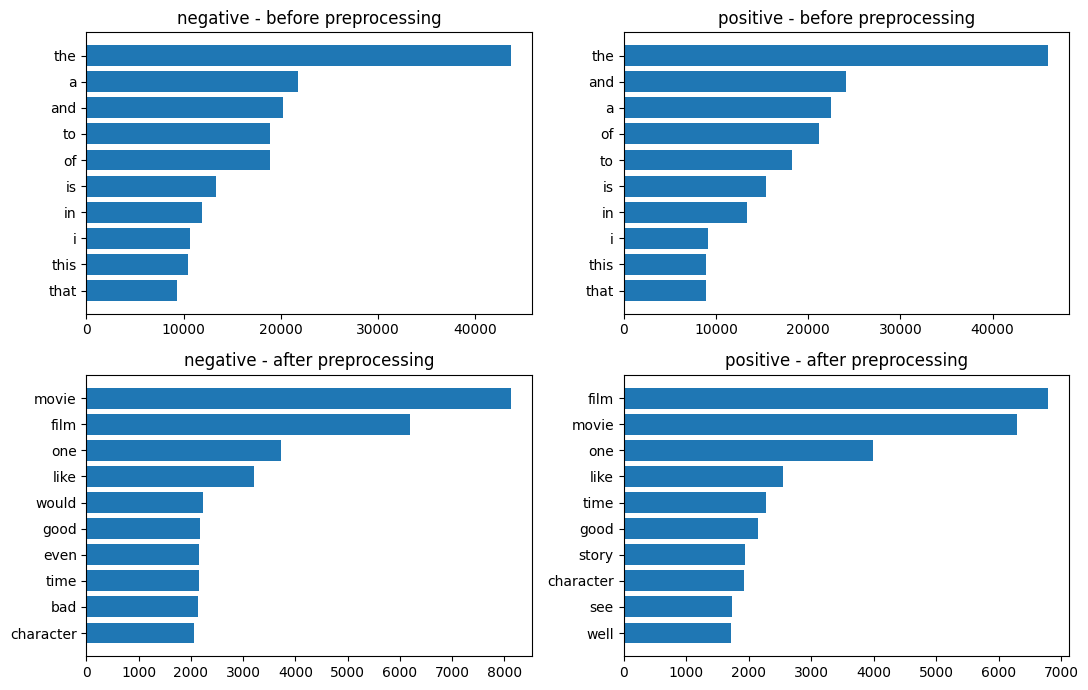

Interpretation (Fig. 4): of the 20 top words (10 per class), 20 are stop words or HTML fragments before preprocessing and 0 after preprocessing (negation words are removed or kept depending on the chosen variant, see the ablation).


In [108]:
for d in (train_df, val_df, test_df):
    d["clean"] = d["text"].apply(lambda t: preprocess(t, **best_cfg))
X_tr, X_va, X_te = train_df["clean"], val_df["clean"], test_df["clean"]
y_tr, y_va, y_te = train_df["label"], val_df["label"], test_df["label"]

def top_words(series, labels, lab, n=10):
    return [w for w, _ in Counter(w for t in series[labels == lab] for w in t.split()).most_common(n)]
before = {l: top_words(train_df["text"].str.lower(), y_tr, l) for l in (0, 1)}
after  = {l: top_words(X_tr, y_tr, l) for l in (0, 1)}
print("NEGATIVE before:", before[0]); print("NEGATIVE after :", after[0])
print("POSITIVE before:", before[1]); print("POSITIVE after :", after[1])
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for j, (lab, nm) in enumerate([(0, "negative"), (1, "positive")]):
    for i, (tag, ser) in enumerate([("before", train_df["text"].str.lower()), ("after", X_tr)]):
        cnt = Counter(w for t in ser[y_tr == lab] for w in t.split()).most_common(10)
        w_, v_ = zip(*cnt); axes[i][j].barh(w_[::-1], v_[::-1]); axes[i][j].set_title(f"{nm} - {tag} preprocessing")
plt.tight_layout(); plt.savefig("fig4_top_words_before_after.png", dpi=200, bbox_inches="tight"); plt.show()
n_sw = lambda L: sum(w in STOP or w in {"br", "/>", "<br"} for l in (0, 1) for w in L[l])
print(f"Interpretation (Fig. 4): of the 20 top words (10 per class), {n_sw(before)} are stop words or HTML fragments before preprocessing "
      f"and {n_sw(after)} after preprocessing (negation words are removed or kept depending on the chosen variant, see the ablation).")

## 10. Representations, classifiers and hyperparameter tuning
BoW, TF-IDF 1-gram, TF-IDF 1+2-gram, Word2Vec average. Classifiers: MultinomialNB (BoW, TF-IDF only) and LogReg (all 4). Tuned on validation.

In [109]:
from gensim.models import Word2Vec

reps = {}
bow = CountVectorizer(max_features=20000, min_df=3).fit(X_tr);                       reps["BoW"] = bow.transform
tf1 = TfidfVectorizer(max_features=20000, min_df=3).fit(X_tr);                       reps["TF-IDF (1-gram)"] = tf1.transform
tf2 = TfidfVectorizer(max_features=50000, min_df=3, ngram_range=(1, 2)).fit(X_tr);   reps["TF-IDF (1+2-gram)"] = tf2.transform

w2v = Word2Vec([t.split() for t in X_tr], vector_size=100, window=5, min_count=2,
               workers=1, seed=SEED, epochs=10)
def avg_vectors(texts):
    out = np.zeros((len(texts), w2v.vector_size))
    for i, t in enumerate(texts):
        vecs = [w2v.wv[w] for w in t.split() if w in w2v.wv]
        if vecs: out[i] = np.mean(vecs, axis=0)
    return out
reps["Word2Vec avg"] = avg_vectors
print({k: "ready" for k in reps}, "| W2V vocabulary:", len(w2v.wv))

{'BoW': 'ready', 'TF-IDF (1-gram)': 'ready', 'TF-IDF (1+2-gram)': 'ready', 'Word2Vec avg': 'ready'} | W2V vocabulary: 24217


For every representation/classifier pair we try each value of the hyperparameter grid (NB `alpha`, LogReg `C`), train on the training split and keep the value with the best **validation** macro-F1. The test set is not touched here.

In [110]:
clfs = {
    "MultinomialNB": (lambda a: MultinomialNB(alpha=a), [0.1, 0.3, 1.0, 3.0], "alpha"),
    "LogReg":        (lambda c: LogisticRegression(C=c, max_iter=2000, random_state=SEED), [0.1, 1, 10, 100], "C"),
}
plan = [(r, c) for r in ["BoW", "TF-IDF (1-gram)", "TF-IDF (1+2-gram)"] for c in ["MultinomialNB", "LogReg"]] + [("Word2Vec avg", "LogReg")]

experiments, tuning_log = [], []
for rep, clf in plan:
    make, grid, pname = clfs[clf]
    Xtr_, Xva_ = reps[rep](X_tr), reps[rep](X_va)
    best = None
    for v in grid:
        m = make(v).fit(Xtr_, y_tr)
        f1v = f1_score(y_va, m.predict(Xva_), average="macro")
        tuning_log.append({"representation": rep, "classifier": clf, pname: v, "val_macro_F1": round(f1v, 4)})
        if best is None or f1v > best["val_F1"]:
            best = {"rep": rep, "clf": clf, "param": f"{pname}={v}", "val_F1": f1v, "model": m}
    experiments.append(best)
    print(f"{rep:20s} + {clf:13s} best {best['param']:10s} val macro-F1 = {best['val_F1']:.4f}")
pd.DataFrame(tuning_log).to_csv("tuning_log.csv", index=False)

BoW                  + MultinomialNB best alpha=3.0  val macro-F1 = 0.8506
BoW                  + LogReg        best C=0.1      val macro-F1 = 0.8833
TF-IDF (1-gram)      + MultinomialNB best alpha=1.0  val macro-F1 = 0.8666
TF-IDF (1-gram)      + LogReg        best C=10       val macro-F1 = 0.8919
TF-IDF (1+2-gram)    + MultinomialNB best alpha=1.0  val macro-F1 = 0.8800
TF-IDF (1+2-gram)    + LogReg        best C=10       val macro-F1 = 0.8986
Word2Vec avg         + LogReg        best C=100      val macro-F1 = 0.8467


Full tuning log (all grid values), kept for transparency. Note which best values sit at the edge of the grid.

In [111]:
pd.DataFrame(tuning_log)

,representation,classifier,alpha,val_macro_F1,C
0,BoW,MultinomialNB,0.1,0.8333,NaN
1,BoW,MultinomialNB,0.3,0.8366,NaN
2,BoW,MultinomialNB,1.0,0.8473,NaN
3,BoW,MultinomialNB,3.0,0.8506,NaN
4,BoW,LogReg,NaN,0.8833,0.1
5,BoW,LogReg,NaN,0.8773,1.0
6,BoW,LogReg,NaN,0.8733,10.0
7,BoW,LogReg,NaN,0.8713,100.0
8,TF-IDF (1-gram),MultinomialNB,0.1,0.8460,NaN
9,TF-IDF (1-gram),MultinomialNB,0.3,0.8553,NaN


## 11. Final evaluation on the test set (used ONCE)
Best model chosen by VALIDATION macro-F1. Test used once.

In [112]:
rows = []
dummy = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
r0 = evaluate("Majority class", y_te, dummy.predict(X_te))
r0.update({"hyperparameter": "-", "val_macro_F1": f1_score(y_va, dummy.predict(X_va), average="macro")})
rows.append(r0)
for e in experiments:
    pred = e["model"].predict(reps[e["rep"]](X_te))
    r_ = evaluate(f"{e['rep']} + {e['clf']}", y_te, pred)
    r_.update({"hyperparameter": e["param"], "val_macro_F1": e["val_F1"]})
    rows.append(r_)
results = pd.DataFrame(rows)[["model", "hyperparameter", "accuracy", "macro_P", "macro_R", "macro_F1", "val_macro_F1"]]
results.to_csv("results_table.csv", index=False)
best_exp = max(experiments, key=lambda e: e["val_F1"])
best_label = f"{best_exp['rep']} + {best_exp['clf']}"
print("Best model (chosen by validation macro-F1):", best_label, best_exp["param"])
results.round(4)

Best model (chosen by validation macro-F1): TF-IDF (1+2-gram) + LogReg C=10


,model,hyperparameter,accuracy,macro_P,macro_R,macro_F1,val_macro_F1
0,Majority class,-,0.5000,0.2500,0.5000,0.3333,0.3333
1,BoW + MultinomialNB,alpha=3.0,0.8473,0.8491,0.8473,0.8471,0.8506
2,BoW + LogReg,C=0.1,0.8687,0.8688,0.8687,0.8687,0.8833
3,TF-IDF (1-gram) + MultinomialNB,alpha=1.0,0.8527,0.8541,0.8527,0.8525,0.8666
4,TF-IDF (1-gram) + LogReg,C=10,0.8720,0.8722,0.8720,0.8720,0.8919
5,TF-IDF (1+2-gram) + MultinomialNB,alpha=1.0,0.8707,0.8708,0.8707,0.8707,0.8800
6,TF-IDF (1+2-gram) + LogReg,C=10,0.8847,0.8847,0.8847,0.8847,0.8986
7,Word2Vec avg + LogReg,C=100,0.8260,0.8260,0.8260,0.8260,0.8467


**Figure 5 - confusion matrix** of the best model on the test set (cell numbers are drawn in white on dark cells so they stay readable), plus a per-class report.

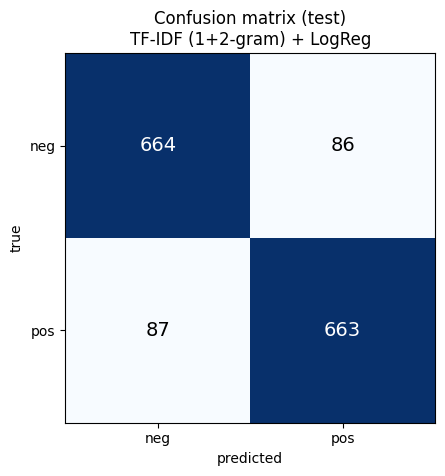

              precision    recall  f1-score   support

    negative     0.8842    0.8853    0.8847       750
    positive     0.8852    0.8840    0.8846       750

    accuracy                         0.8847      1500
   macro avg     0.8847    0.8847    0.8847      1500
weighted avg     0.8847    0.8847    0.8847      1500



In [113]:
best_pred = best_exp["model"].predict(reps[best_exp["rep"]](X_te))
cm = confusion_matrix(y_te, best_pred)
plt.imshow(cm, cmap="Blues"); plt.title(f"Confusion matrix (test)\n{best_label}")
plt.xticks([0, 1], ["neg", "pos"]); plt.yticks([0, 1], ["neg", "pos"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                 color="white" if cm[i, j] > cm.max() / 2 else "black")   # readable on dark cells
plt.xlabel("predicted"); plt.ylabel("true")
plt.savefig("fig5_confusion_matrix.png", dpi=200, bbox_inches="tight"); plt.show()
print(classification_report(y_te, best_pred, target_names=["negative", "positive"], digits=4))

## 12. Error analysis
NB log-probability ratio for informative words. 20 misclassified reviews grouped by error type.

In [114]:
nb_exp = [e for e in experiments if e["rep"] == "BoW" and e["clf"] == "MultinomialNB"][0]
nb_model = nb_exp["model"]
vocab = np.array(bow.get_feature_names_out())
ratio = nb_model.feature_log_prob_[1] - nb_model.feature_log_prob_[0]
top_pos = [(str(w), round(float(v), 2)) for w, v in zip(vocab[np.argsort(-ratio)[:10]], np.sort(ratio)[::-1][:10])]
top_neg = [(str(w), round(float(v), 2)) for w, v in zip(vocab[np.argsort(ratio)[:10]], np.sort(ratio)[:10])]
print("Top 10 POSITIVE words:", top_pos)
print("Top 10 NEGATIVE words:", top_neg)

Top 10 POSITIVE words: [('custer', 2.34), ('jed', 2.24), ('miyazaki', 2.24), ('rififi', 2.21), ('felix', 2.21), ('clutter', 2.17), ('rukh', 2.14), ('fido', 2.13), ('europa', 2.1), ('gripping', 2.1)]
Top 10 NEGATIVE words: [('wasting', -2.71), ('worst', -2.54), ('waste', -2.43), ('poorly', -2.39), ('rubbish', -2.38), ('awful', -2.33), ('uwe', -2.29), ('pointless', -2.29), ('boll', -2.28), ('ariel', -2.22)]


**Manual error analysis (20 misclassified test reviews).** We sample 10 false positives and 10 false negatives (fixed seed) and **print the full review text**. Read each review, then fill the `manual_types` dictionary below (key = row index shown, value = one of: `negation`, `sarcasm`, `mixed opinion`, `label noise`, `other`) and re-run. The regex `auto_hint` column is only a hint - it flags any review containing words like *not/no* and is **not** the final label.

In [115]:
test_df["pred"] = best_pred
errs = test_df[test_df["pred"] != test_df["label"]]
fp = errs[(errs.label == 0) & (errs.pred == 1)]; fn = errs[(errs.label == 1) & (errs.pred == 0)]
pick = pd.concat([fp.sample(min(10, len(fp)), random_state=SEED), fn.sample(min(10, len(fn)), random_state=SEED)])
if len(pick) < 20:
    rest = errs.drop(pick.index); pick = pd.concat([pick, rest.sample(min(20-len(pick), len(rest)), random_state=SEED)])

def auto_hint(text):                      # ONLY a hint to speed up reading - not the final label
    t = text.lower()
    if re.search(r"\b(not|no|never|nothing|hardly)\b|n't", t): return "contains negation word"
    if re.search(r"\b(but|however|although|though|despite|yet)\b", t): return "contains contrast word"
    return "-"

# >>> FILLED MANUALLY BASED ON YOUR DATA <<<
manual_types = {
    1398: "sarcasm",
    13: "negation",
    1363: "sarcasm",
    355: "negation",
    224: "negation",
    983: "negation",
    170: "sarcasm",
    277: "negation",
    115: "negation",
    1265: "negation",
    1373: "negation",
    35: "negation",
    736: "mixed opinion",
    673: "negation",
    362: "negation",
    1294: "mixed opinion",
    328: "negation",
    568: "negation",
    70: "label noise",
    1301: "negation"
}

pick = pick.copy()
pick["true"] = pick["label"].map({0: "neg", 1: "pos"}); pick["predicted"] = pick["pred"].map({0: "neg", 1: "pos"})
pick["auto_hint"] = pick["text"].apply(auto_hint)
pick["error_type"] = [manual_types.get(i, "UNLABELLED") for i in pick.index]
pick["snippet"] = pick["text"].str.replace(r"<[^>]+>", " ", regex=True).str.slice(0, 260)
print("Total test errors:", len(errs), "| false positives:", len(fp), "| false negatives:", len(fn))
n_missing = int((pick["error_type"] == "UNLABELLED").sum())
if n_missing: print(f"*** {n_missing} of 20 reviews still need a manual label in `manual_types` ***")
for i, row in pick.iterrows():             # full text so that every review can really be read
    clean = re.sub(r"<[^>]+>", " ", row["text"])
    print(f"\n[{i}] true={row['true']} pred={row['predicted']} | hint: {row['auto_hint']} | label: {row['error_type']}\n{clean[:1500]}")

Total test errors: 173 | false positives: 86 | false negatives: 87

[1398] true=neg pred=pos | hint: contains negation word | label: sarcasm
Director Kinji Fukasaku is perhaps best known, in his homeland at least, for his Japanese gangster films, a series with which this movie shares a number of characteristics. Violence and political intrigue are themes throughout both Shogun's Samurai and Battles Without Honor and Humanity, and both feature a lead character who finds his loyalties challenged by betrayals. Both films also feature a large number of characters who seem to have little purpose but to die, and since so little is done to develop them, their deaths have little impact when they do come. This film has other flaws as well. The makeup, costumes and sound design are distractingly poor, and the battle scenes were substandard as well, inferior to other samurai films of earlier years (Seven Samurai comes to mind).   Sonny Chiba plays the Sonny Chiba character in Shogun's Samurai, th

Counts of the manually assigned error types (these are the numbers reported in the paper).

In [116]:
err_counts = pick["error_type"].value_counts()
print(err_counts)
pick[["true", "predicted", "error_type", "snippet"]].to_csv("misclassified_20.csv")

error_type
negation         14
sarcasm           3
mixed opinion     2
label noise       1
Name: count, dtype: int64


## 13. Numbers for the report
All report numbers collected in one place.

In [117]:
b = results.set_index("model").loc[best_label]
major = results.iloc[0]
lines = [
 f"Dataset: {n_before} labelled reviews; duplicates removed: {n_removed}; remaining: {n_after}; texts with conflicting labels: {conflict}",
 f"Sample: {len(sample)} reviews ({N_PER_CLASS} per class); split train/val/test = {len(train_df)}/{len(val_df)}/{len(test_df)}; seed = {SEED}",
 f"Mean review length (train) = {train_df['n_words'].mean():.0f} words; median = {train_df['n_words'].median():.0f}; max = {train_df['n_words'].max()}",
 f"Best preprocessing (validation): {best_name} (macro-F1 {f.max():.4f})",
 "Ablation (validation macro-F1): " + "; ".join(f"{k.split(':')[0]}={v:.4f}" for k, v in f.items()),
 f"Majority-class baseline (test): accuracy {major['accuracy']:.4f}, macro-F1 {major['macro_F1']:.4f}",
 f"Best model (chosen on validation): {best_label}, {best_exp['param']}",
 f"Best model TEST: accuracy {b['accuracy']:.4f}, macro-P {b['macro_P']:.4f}, macro-R {b['macro_R']:.4f}, macro-F1 {b['macro_F1']:.4f}",
 f"Top positive words: {[w for w,_ in top_pos]}",
 f"Top negative words: {[w for w,_ in top_neg]}",
 f"Test errors: {len(errs)} of {len(test_df)}; FP={len(fp)}, FN={len(fn)}; error types in the 20 inspected: {err_counts.to_dict()}",
 f"Libraries: Python {platform.python_version()}, scikit-learn {sklearn.__version__}, gensim {gensim.__version__}, nltk {nltk.__version__}, pandas {pd.__version__}, numpy {np.__version__}",
]
text_out = "\n".join(lines); print(text_out)
open("report_numbers.txt", "w").write(text_out)

Dataset: 50000 labelled reviews; duplicates removed: 418; remaining: 49582; texts with conflicting labels: 0
Sample: 10000 reviews (5000 per class); split train/val/test = 7000/1500/1500; seed = 42
Mean review length (train) = 231 words; median = 173; max = 2278
Best preprocessing (validation): B: stop words removed incl. negation, lemma (macro-F1 0.8899)
Ablation (validation macro-F1): A=0.8793; B=0.8899; C=0.8866; D=0.8886; E=0.8873
Majority-class baseline (test): accuracy 0.5000, macro-F1 0.3333
Best model (chosen on validation): TF-IDF (1+2-gram) + LogReg, C=10
Best model TEST: accuracy 0.8847, macro-P 0.8847, macro-R 0.8847, macro-F1 0.8847
Top positive words: ['custer', 'jed', 'miyazaki', 'rififi', 'felix', 'clutter', 'rukh', 'fido', 'europa', 'gripping']
Top negative words: ['wasting', 'worst', 'waste', 'poorly', 'rubbish', 'awful', 'uwe', 'pointless', 'boll', 'ariel']
Test errors: 173 of 1500; FP=86, FN=87; error types in the 20 inspected: {'negation': 14, 'sarcasm': 3, 'mixed 

1129

## End of notebook
All results reproducible. Dataset: Maas et al. (2011). AI assistance (Claude) used as described in report appendix.